In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Visual style setup
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# 1. Load Assignment 7 Baselines
lab7_sum_path = 'c:/Users/VIVEK/Desktop/NLP Lab/AASIGNMENT_7/summary_metrics.csv'
lab7_tag_path = 'c:/Users/VIVEK/Desktop/NLP Lab/AASIGNMENT_7/per_tag_f1_results.csv'

lab7_sum = pd.read_csv(lab7_sum_path)
lab7_tag = pd.read_csv(lab7_tag_path)

# Filter HMM to HMM Forward-Backward (or Forward Viterbi)
lab7_sum_filtered = lab7_sum[lab7_sum['model'].isin(['Naive Bayes', 'HMM Forward-Backward'])].copy()
lab7_sum_filtered['model'] = lab7_sum_filtered['model'].replace({'HMM Forward-Backward': 'HMM'})

lab7_tag_filtered = lab7_tag[lab7_tag['model'].isin(['Naive Bayes', 'HMM Forward-Backward'])].copy()
lab7_tag_filtered['model'] = lab7_tag_filtered['model'].replace({'HMM Forward-Backward': 'HMM'})

# 2. Load Assignment 9 Results
memm_sum = pd.read_csv('memm_summary_metrics.csv')
memm_tag = pd.read_csv('memm_per_tag_results.csv')

crf_sum = pd.read_csv('crf_summary_metrics.csv')
crf_tag = pd.read_csv('crf_per_tag_results.csv')

# 3. Combine into unified dataframes
comparison_sum_df = pd.concat([lab7_sum_filtered, memm_sum, crf_sum], ignore_index=True)
comparison_tag_df = pd.concat([lab7_tag_filtered, memm_tag, crf_tag], ignore_index=True)

# Save Master Comparative CSVs
comparison_sum_df.to_csv('comparative_summary_metrics.csv', index=False)
comparison_tag_df.to_csv('comparative_per_tag_f1.csv', index=False)

print("Master Comparative CSVs created:")
print(" - comparative_summary_metrics.csv")
print(" - comparative_per_tag_f1.csv")

Master Comparative CSVs created:
 - comparative_summary_metrics.csv
 - comparative_per_tag_f1.csv


In [3]:
# Format metrics as percentage strings for readable display
display_summary = comparison_sum_df.copy()
display_summary['Accuracy (%)'] = (display_summary['accuracy'] * 100).map('{:.2f}%'.format)
display_summary['Macro F1 (%)'] = (display_summary['macro_f1'] * 100).map('{:.2f}%'.format)
display_summary['Weighted F1 (%)'] = (display_summary['weighted_f1'] * 100).map('{:.2f}%'.format)

print("=== Overall Model Comparison: Development Split ===")
dev_table = display_summary[display_summary['split'] == 'dev'][['model', 'Accuracy (%)', 'Macro F1 (%)', 'Weighted F1 (%)']]
print(dev_table.to_string(index=False))

print("\n=== Overall Model Comparison: Test Split ===")
test_table = display_summary[display_summary['split'] == 'test'][['model', 'Accuracy (%)', 'Macro F1 (%)', 'Weighted F1 (%)']]
print(test_table.to_string(index=False))

=== Overall Model Comparison: Development Split ===
      model Accuracy (%) Macro F1 (%) Weighted F1 (%)
Naive Bayes       92.47%       83.31%          92.49%
        HMM       93.07%       90.82%          93.03%
       MEMM       96.00%       96.17%          95.98%
        CRF       96.40%       96.53%          96.39%

=== Overall Model Comparison: Test Split ===
      model Accuracy (%) Macro F1 (%) Weighted F1 (%)
Naive Bayes       92.57%       84.44%          92.59%
        HMM       92.95%       86.35%          92.92%
       MEMM       96.18%       92.29%          96.17%
        CRF       96.49%       92.90%          96.49%


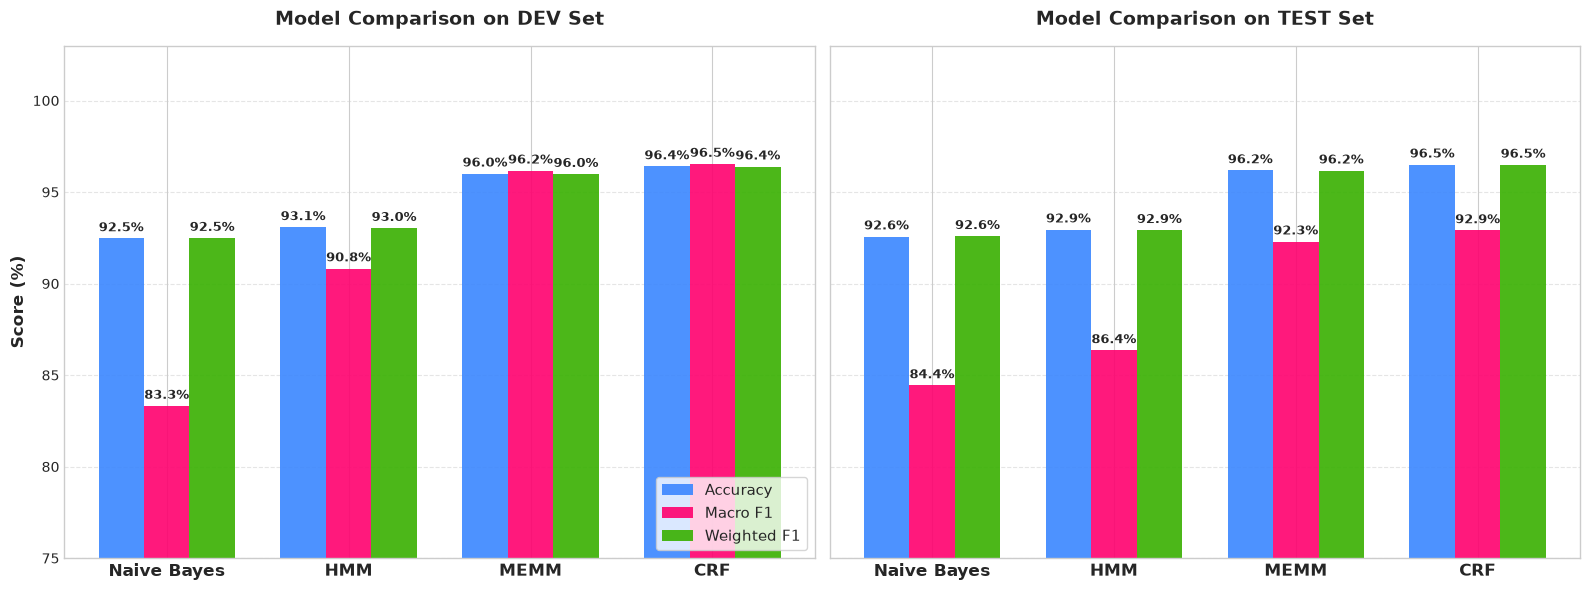

In [4]:
# Plot Overall Model Performance (Accuracy, Macro F1, Weighted F1)
models = ['Naive Bayes', 'HMM', 'MEMM', 'CRF']
splits = ['dev', 'test']

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
palette = ['#457b9d', '#2a9d8f', '#e76f51', '#7209b7']

for ax_idx, split_name in enumerate(splits):
    ax = axes[ax_idx]
    split_data = comparison_sum_df[comparison_sum_df['split'] == split_name]
    
    x = np.arange(len(models))
    width = 0.25
    
    accs = [split_data.loc[split_data['model'] == m, 'accuracy'].values[0] * 100 for m in models]
    macro_f1s = [split_data.loc[split_data['model'] == m, 'macro_f1'].values[0] * 100 for m in models]
    weight_f1s = [split_data.loc[split_data['model'] == m, 'weighted_f1'].values[0] * 100 for m in models]
    
    rects1 = ax.bar(x - width, accs, width, label='Accuracy', color='#3a86ff', alpha=0.9)
    rects2 = ax.bar(x, macro_f1s, width, label='Macro F1', color='#ff006e', alpha=0.9)
    rects3 = ax.bar(x + width, weight_f1s, width, label='Weighted F1', color='#38b000', alpha=0.9)
    
    # Value annotations on top of bars
    for rect in rects1:
        h = rect.get_height()
        ax.annotate(f'{h:.1f}%', (rect.get_x() + rect.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')
    for rect in rects2:
        h = rect.get_height()
        ax.annotate(f'{h:.1f}%', (rect.get_x() + rect.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')
    for rect in rects3:
        h = rect.get_height()
        ax.annotate(f'{h:.1f}%', (rect.get_x() + rect.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')
        
    ax.set_title(f'Model Comparison on {split_name.upper()} Set', fontsize=14, fontweight='bold', pad=15)
    ax.set_xticks(x)
    ax.set_xticklabels(models, fontsize=12, fontweight='bold')
    ax.set_ylim(75, 103)
    ax.set_ylabel('Score (%)' if ax_idx == 0 else '', fontsize=12, fontweight='bold')
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    if ax_idx == 0:
        ax.legend(frameon=True, fontsize=11, loc='lower right')

plt.tight_layout()
plt.savefig('overall_model_comparison.png', dpi=300)
plt.show()

In [5]:
# Build pivot tables of Per-Tag F1 scores for Dev and Test
all_tags = sorted(list(comparison_tag_df['tag'].unique()))

pivot_dev = comparison_tag_df[comparison_tag_df['split'] == 'dev'].pivot(index='tag', columns='model', values='f1')[models]
pivot_test = comparison_tag_df[comparison_tag_df['split'] == 'test'].pivot(index='tag', columns='model', values='f1')[models]

print("=== Per-Tag F1 Scores on Development Set ===")
print((pivot_dev * 100).round(2).to_string())

print("\n=== Per-Tag F1 Scores on Test Set ===")
print((pivot_test * 100).round(2).to_string())

=== Per-Tag F1 Scores on Development Set ===
model    Naive Bayes     HMM    MEMM     CRF
tag                                         
CC_CCD         94.84   96.57   98.50   98.86
CC_CCS         96.79   96.83   98.68   98.55
DM_DMD         88.31   91.47   95.27   97.02
JJ             86.91   88.73   91.97   92.77
N_NN           90.75   91.57   93.74   94.22
N_NNP          83.62   83.38   88.25   89.43
N_NST          88.97   91.36   98.80   99.28
PR_PRF         91.64   98.38   99.35  100.00
PR_PRL         72.80   79.84   96.23   95.73
PR_PRP         89.68   94.54   97.52   97.99
PR_PRQ         78.26   97.96  100.00   98.04
PSP            98.47   98.43   99.69   99.77
QT_QTC         91.66   86.99   97.33   97.38
QT_QTF         86.43   92.47   94.92   94.69
QT_QTO         60.13   81.67   92.91   93.65
RB             61.19   80.00   87.07   86.34
RD_PUNC        99.25   99.92  100.00  100.00
RD_SYM         91.91   95.25  100.00  100.00
RP_INJ          0.00  100.00  100.00  100.00
RP_INTF   

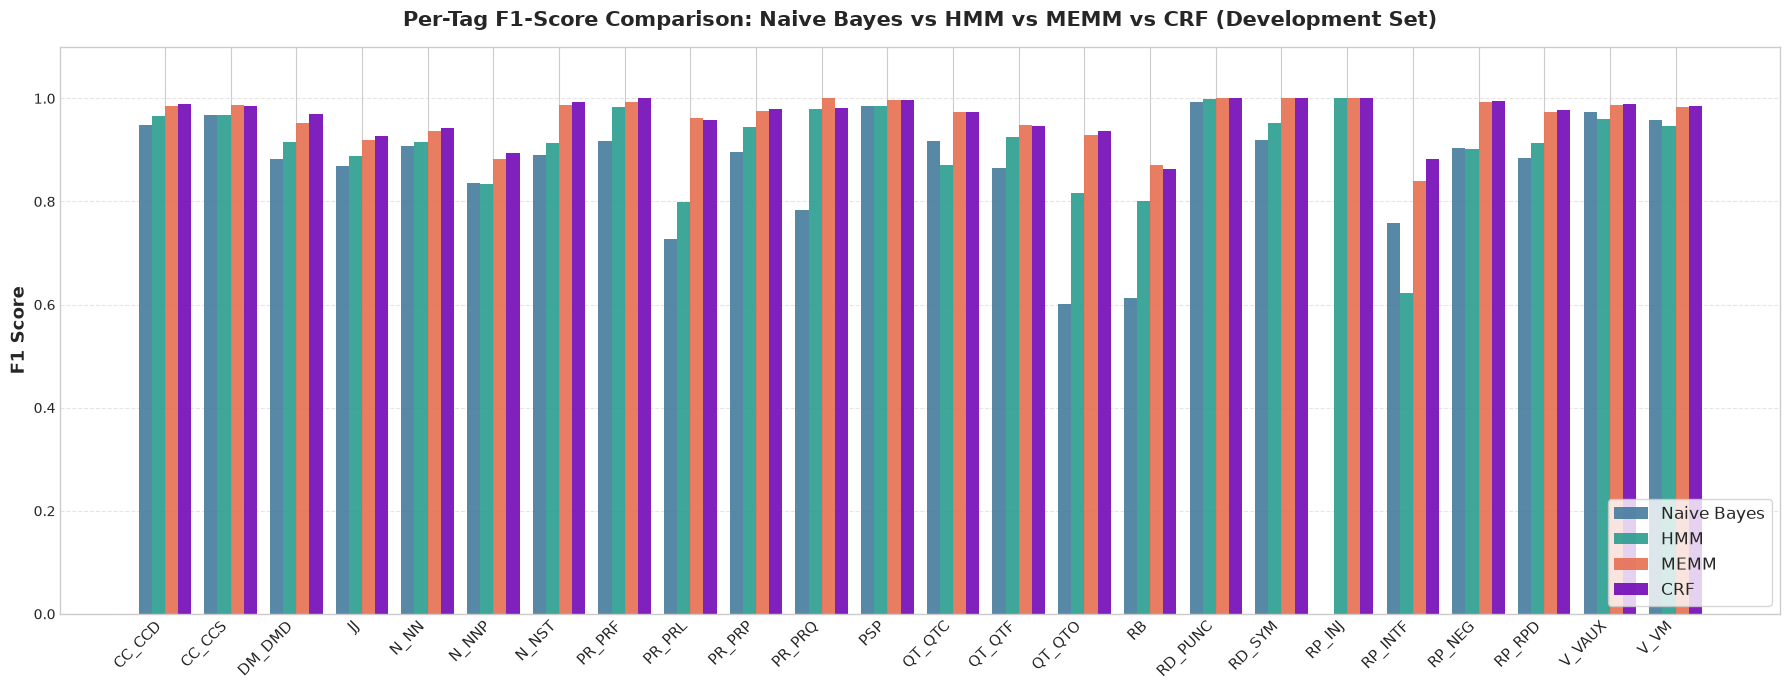

In [6]:
fig, ax = plt.subplots(figsize=(18, 7))

x = np.arange(len(all_tags))
width = 0.20

colors = ['#457b9d', '#2a9d8f', '#e76f51', '#7209b7']

for idx, model_name in enumerate(models):
    f1_vals = [pivot_dev.loc[t, model_name] if t in pivot_dev.index and not np.isnan(pivot_dev.loc[t, model_name]) else 0.0 for t in all_tags]
    offset = (idx - 1.5) * width
    ax.bar(x + offset, f1_vals, width, label=model_name, color=colors[idx], alpha=0.9)

ax.set_ylabel('F1 Score', fontsize=13, fontweight='bold')
ax.set_title('Per-Tag F1-Score Comparison: Naive Bayes vs HMM vs MEMM vs CRF (Development Set)', fontsize=15, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(all_tags, rotation=45, ha='right', fontsize=11)
ax.set_ylim(0, 1.1)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(frameon=True, fontsize=12, loc='lower right')

plt.tight_layout()
plt.savefig('per_tag_comparison_dev.png', dpi=300)
plt.show()

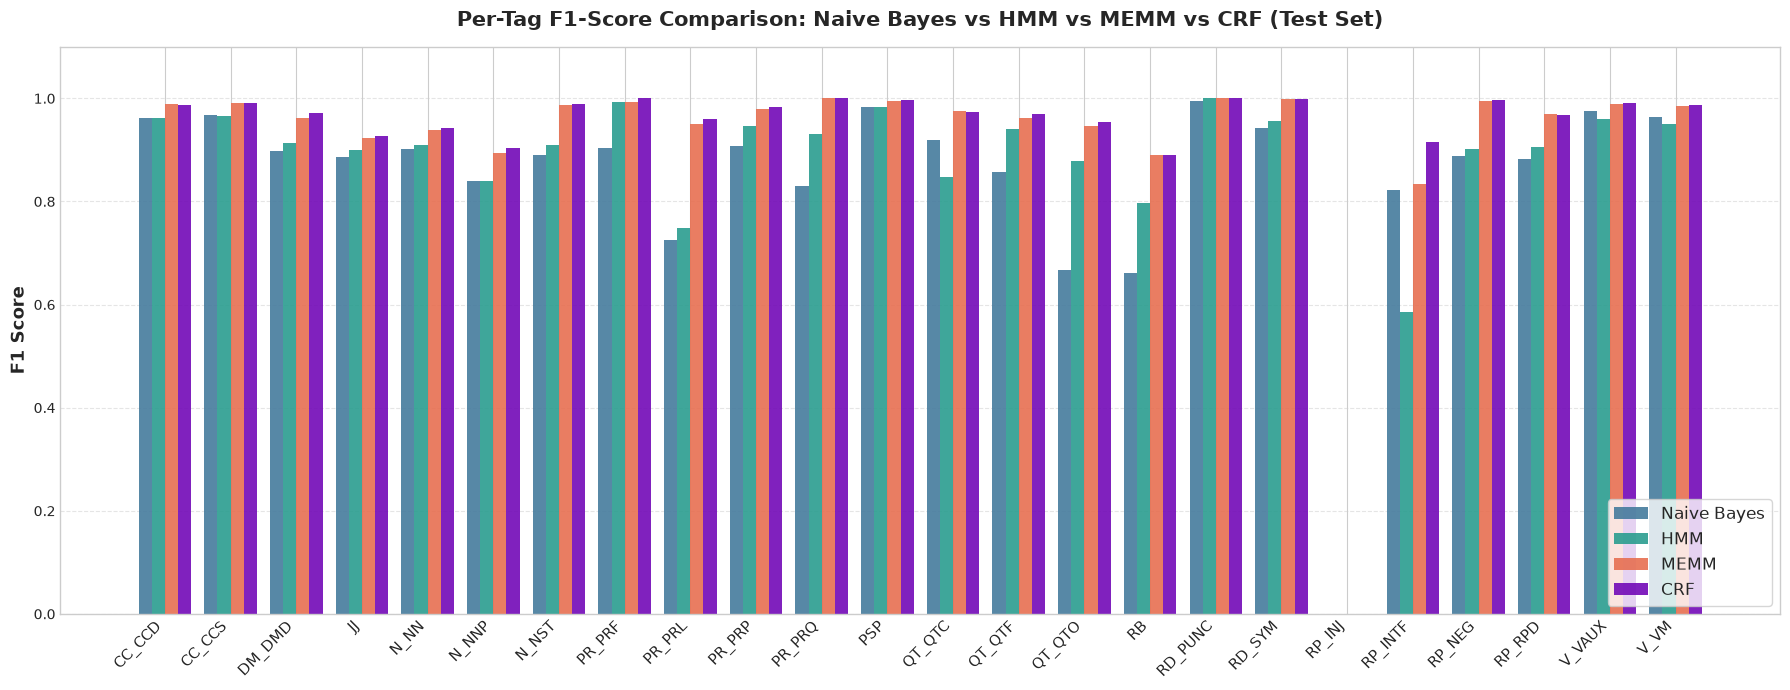

In [7]:
fig, ax = plt.subplots(figsize=(18, 7))

x = np.arange(len(all_tags))
width = 0.20

colors = ['#457b9d', '#2a9d8f', '#e76f51', '#7209b7']

for idx, model_name in enumerate(models):
    f1_vals = [pivot_test.loc[t, model_name] if t in pivot_test.index and not np.isnan(pivot_test.loc[t, model_name]) else 0.0 for t in all_tags]
    offset = (idx - 1.5) * width
    ax.bar(x + offset, f1_vals, width, label=model_name, color=colors[idx], alpha=0.9)

ax.set_ylabel('F1 Score', fontsize=13, fontweight='bold')
ax.set_title('Per-Tag F1-Score Comparison: Naive Bayes vs HMM vs MEMM vs CRF (Test Set)', fontsize=15, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(all_tags, rotation=45, ha='right', fontsize=11)
ax.set_ylim(0, 1.1)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(frameon=True, fontsize=12, loc='lower right')

plt.tight_layout()
plt.savefig('per_tag_comparison_test.png', dpi=300)
plt.show()

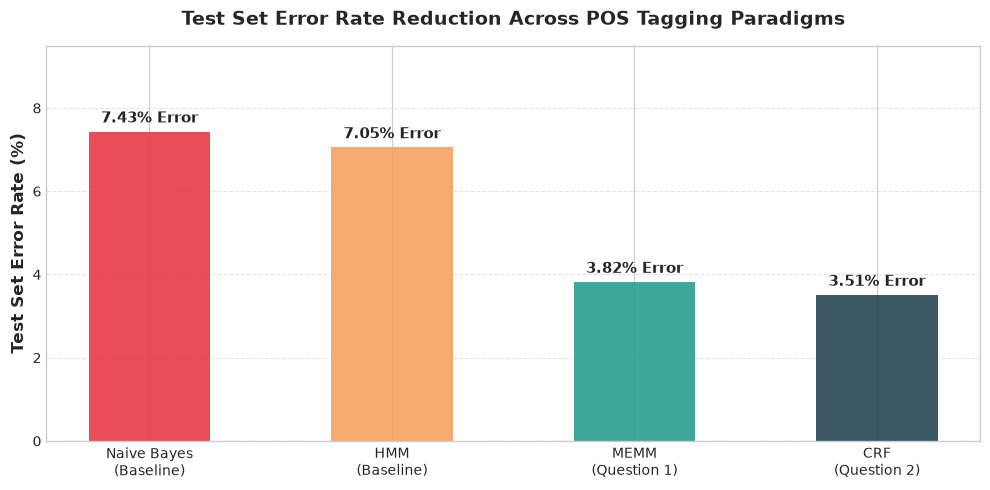

Error Rate Reduction from Naive Bayes to CRF: 52.83% relative reduction!
Error Rate Reduction from HMM to CRF:         50.29% relative reduction!


In [8]:
# Compute error reduction and delta improvement
test_metrics = comparison_sum_df[comparison_sum_df['split'] == 'test'].set_index('model')

nb_acc = test_metrics.loc['Naive Bayes', 'accuracy'] * 100
hmm_acc = test_metrics.loc['HMM', 'accuracy'] * 100
memm_acc = test_metrics.loc['MEMM', 'accuracy'] * 100
crf_acc = test_metrics.loc['CRF', 'accuracy'] * 100

error_nb = 100 - nb_acc
error_hmm = 100 - hmm_acc
error_memm = 100 - memm_acc
error_crf = 100 - crf_acc

fig, ax = plt.subplots(figsize=(10, 5))

model_labels = ['Naive Bayes\n(Baseline)', 'HMM\n(Baseline)', 'MEMM\n(Question 1)', 'CRF\n(Question 2)']
error_rates = [error_nb, error_hmm, error_memm, error_crf]
bars = ax.bar(model_labels, error_rates, color=['#e63946', '#f4a261', '#2a9d8f', '#264653'], width=0.5, alpha=0.9)

for bar in bars:
    h = bar.get_height()
    ax.annotate(f'{h:.2f}% Error', (bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_ylabel('Test Set Error Rate (%)', fontsize=12, fontweight='bold')
ax.set_title('Test Set Error Rate Reduction Across POS Tagging Paradigms', fontsize=14, fontweight='bold', pad=15)
ax.set_ylim(0, 9.5)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('error_rate_comparison.png', dpi=300)
plt.show()

print(f"Error Rate Reduction from Naive Bayes to CRF: {(error_nb - error_crf)/error_nb * 100:.2f}% relative reduction!")
print(f"Error Rate Reduction from HMM to CRF:         {(error_hmm - error_crf)/error_hmm * 100:.2f}% relative reduction!")